In [1]:
print("OASIS INFOBYTE")
print("Data Analytics - Task 1")
print("EDA on Retail Sales Data")

OASIS INFOBYTE
Data Analytics - Task 1
EDA on Retail Sales Data


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
%pip install pandas numpy matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import pandas as pd 
df = pd.read_csv(r"C:\Users\HC\Downloads\retail_sales_dataset .csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [15]:
print("Dataset rows and Columns:")
print(df.shape)

Dataset rows and Columns:
(1000, 9)


In [16]:
print(df.columns.tolist())

['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [18]:
print(df.isnull().sum())

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [21]:
print("Dublicate rows:",df.duplicated().sum())

Dublicate rows: 0


In [22]:
print(df.isnull().sum())

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [23]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


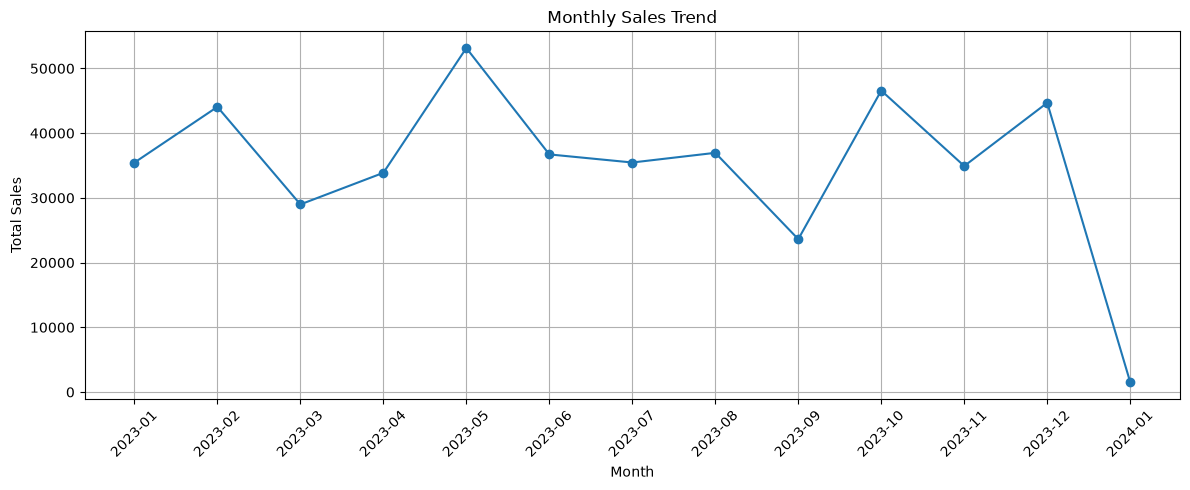

In [29]:
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.to_period("M")
monthly_sales = df.groupby("Month")["Total Amount"].sum()
plt.figure(figsize=(12,5))
plt.plot(monthly_sales.index.astype(str),
         monthly_sales.values,
         marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Observation: Monthly Sales Trend

This line chart shows how total sales change from month to month.
It helps identify months with higher and lower sales.

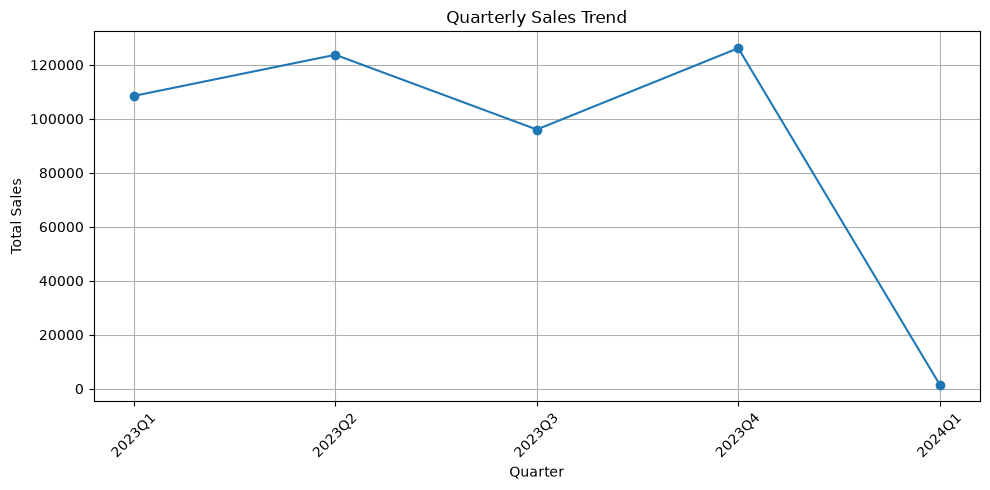

In [30]:
df["Quarter"] = df["Date"].dt.to_period("Q")
quarterly_sales = df.groupby("Quarter")["Total Amount"].sum()
plt.figure(figsize=(10, 5))
plt.plot(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    marker="o")
plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Observation: Quarterly Sales Trend

This chart shows the total sales for each quarter.
A quarter represents three months.
It helps identify which quarter had higher or lower sales.

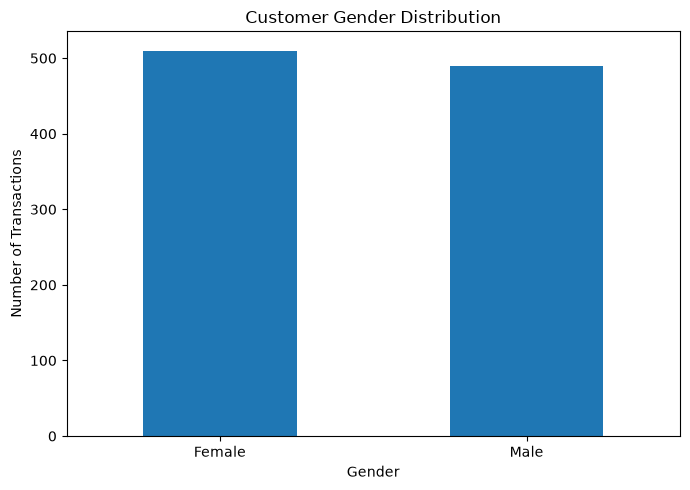

In [31]:
gender_counts = df["Gender"].value_counts()
plt.figure(figsize=(7, 5))
gender_counts.plot(kind="bar")
plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: Customer Gender Distribution

This chart compares the number of transactions by male and female customers. It helps identify which gender has more transactions in this dataset.

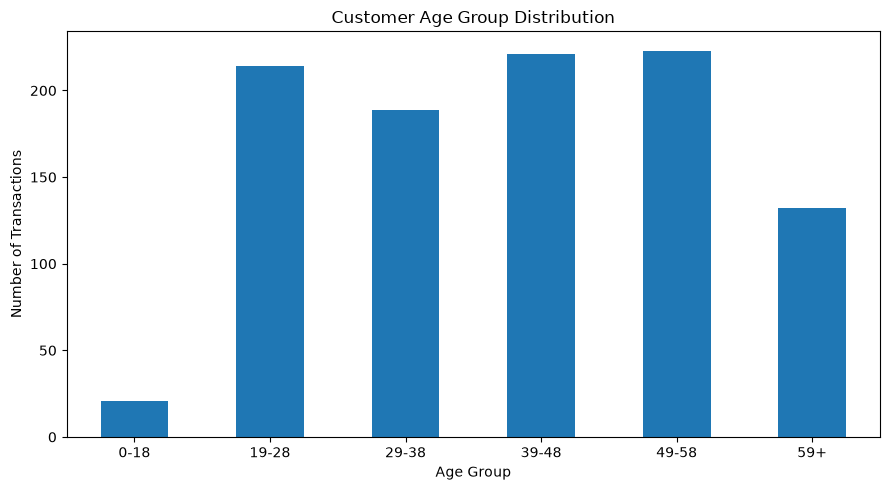

In [32]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 19, 29, 39, 49, 59, 100],
    labels=["0-18", "19-28", "29-38", "39-48", "49-58", "59+"],
    right=False)
age_counts = df["Age Group"].value_counts().sort_index()
plt.figure(figsize=(9, 5))
age_counts.plot(kind="bar")
plt.title("Customer Age Group Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: Customer Age Group Distribution

This chart shows the distribution of transactions across different age groups. It helps identify the age groups that appear most frequently in the dataset.

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


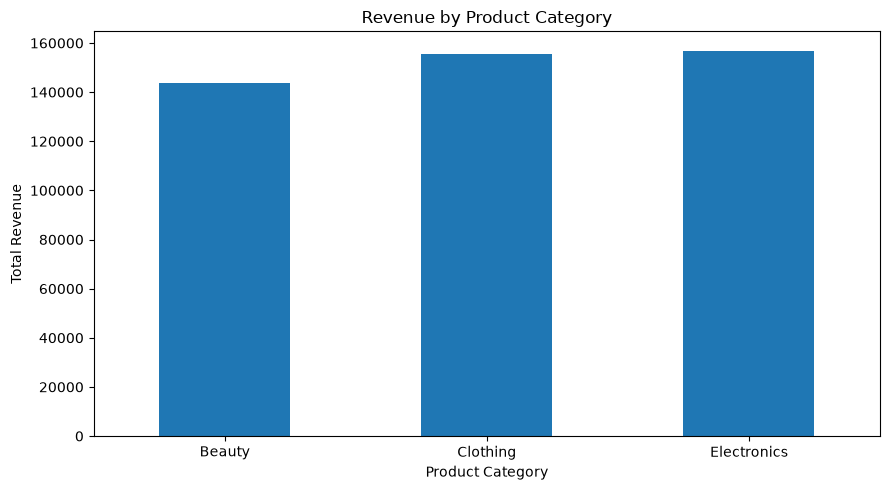

In [33]:
category_sales = df.groupby("Product Category")["Total Amount"].sum()
print(category_sales)
plt.figure(figsize=(9, 5))
category_sales.plot(kind="bar")
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: Revenue by Product Category

This chart compares the total revenue generated by each product category. The category with the highest bar generated the most revenue in this dataset.

In [34]:
print(df.columns.tolist())

['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount', 'Month', 'Quarter', 'Age Group']


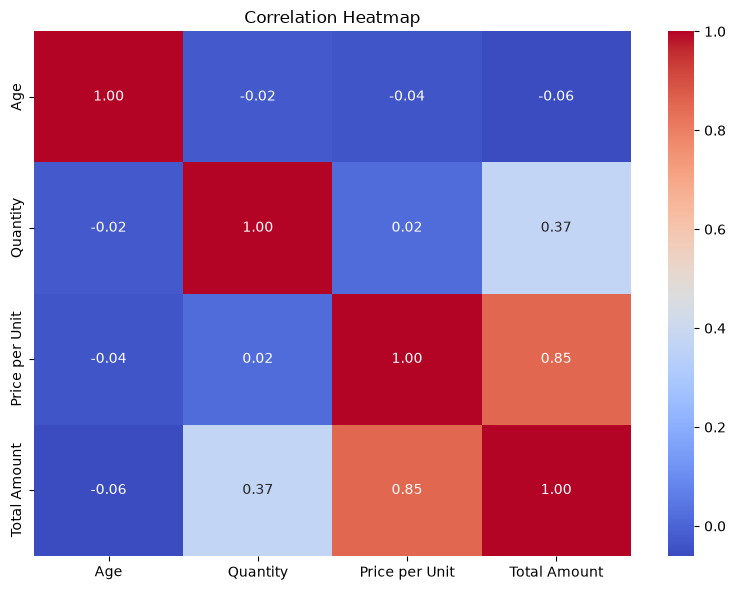

In [35]:
numeric_data = df[
    ["Age", "Quantity", "Price per Unit", "Total Amount"]]
correlation = numeric_data.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Observation: Correlation Heatmap

The heatmap shows the relationships between numerical variables. Values closer to +1 indicate a positive relationship, while values closer to -1 indicate a negative relationship. Values near 0 indicate a weak linear relationship.

In [36]:
numeric_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
print("MEAN")
print(df[numeric_cols].mean())
print("\nMEDIAN")
print(df[numeric_cols].median())
print("\nMODE")
print(df[numeric_cols].mode().iloc[0])
print("\nSTANDARD DEVIATION")
print(df[numeric_cols].std())

MEAN
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

MEDIAN
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

MODE
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

STANDARD DEVIATION
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


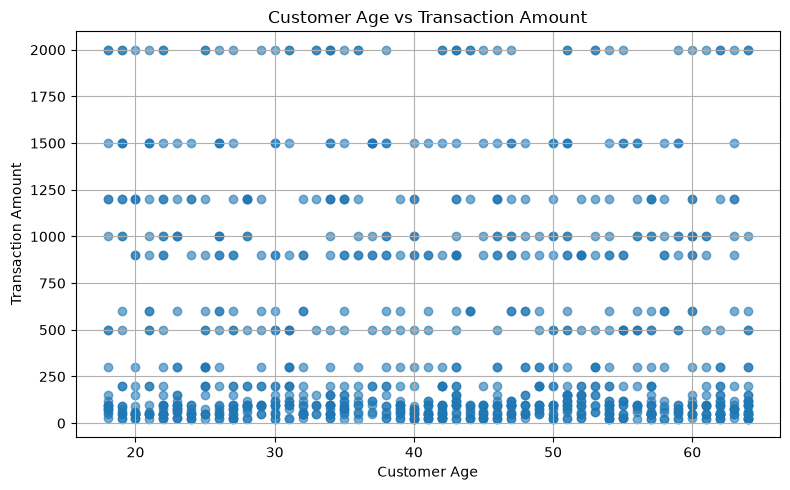

In [37]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Age"], df["Total Amount"], alpha=0.6)
plt.title("Customer Age vs Transaction Amount")
plt.xlabel("Customer Age")
plt.ylabel("Transaction Amount")
plt.grid(True)
plt.tight_layout()
plt.show()

### Observation: Age vs Transaction Amount

This scatter plot shows the relationship between customer age and transaction amount. It helps identify whether transaction values vary across different ages.

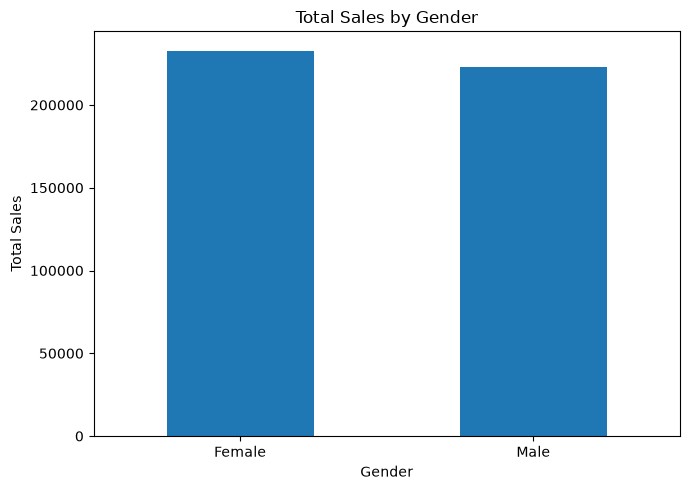

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


In [38]:
gender_sales = df.groupby("Gender")["Total Amount"].sum()
plt.figure(figsize=(7, 5))
gender_sales.plot(kind="bar")
plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print(gender_sales)

In [39]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset shape:", df.shape)

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
Month               0
Quarter             0
Age Group           0
dtype: int64

Duplicate rows: 0

Dataset shape: (1000, 12)


Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


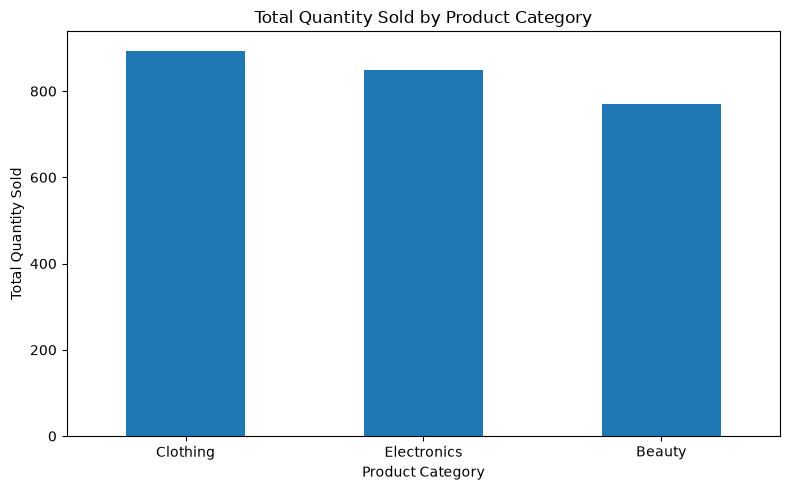

In [40]:
category_quantity = df.groupby("Product Category")["Quantity"].sum()
category_quantity = category_quantity.sort_values(ascending=False)
print(category_quantity)
category_quantity.plot(kind="bar", figsize=(8, 5))
plt.title("Total Quantity Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:
print("Total Revenue:", df["Total Amount"].sum())
print("\nAverage Transaction Amount:", df["Total Amount"].mean())
print("\nBest Revenue Category:")
print(df.groupby("Product Category")["Total Amount"].sum().idxmax())
print("\nBest Quantity Category:")
print(df.groupby("Product Category")["Quantity"].sum().idxmax())
print("\nSales by Gender:")
print(df.groupby("Gender")["Total Amount"].sum())
print("\nSales by Age Group:")
print(df.groupby("Age Group")["Total Amount"].sum())

Total Revenue: 456000

Average Transaction Amount: 456.0

Best Revenue Category:
Electronics

Best Quantity Category:
Clothing

Sales by Gender:
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

Sales by Age Group:
Age Group
0-18      11215
19-28    105370
29-38     98300
39-48     92850
49-58     93980
59+       54285
Name: Total Amount, dtype: int64


# Conclusion and Business Recommendations

## Conclusion

The analysis explored monthly and quarterly sales trends, customer demographics, product categories, and relationships between numerical variables.

## Business Recommendations

1. **Product Planning:** Focus on the category generating the highest revenue and maintain sufficient stock for its demand.

2. **Marketing Strategy:** Use the gender and age-group analysis to design targeted promotions based on observed purchasing patterns.

3. **Sales Planning:** Compare monthly and quarterly trends to identify stronger and weaker periods and plan promotions accordingly.